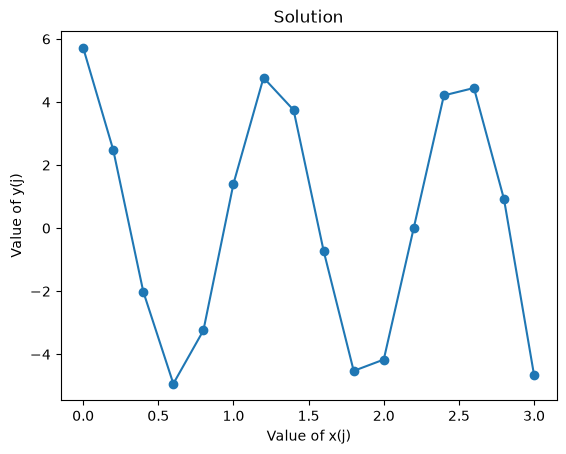

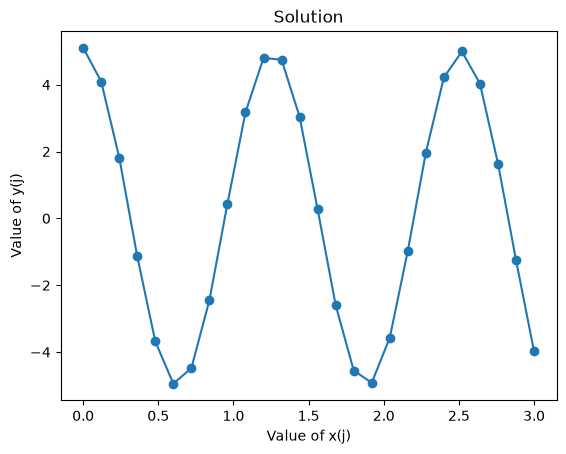

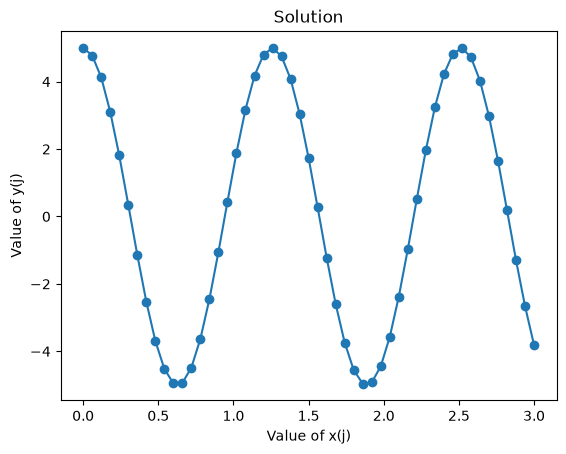

In [11]:
##LU Algorithm

import numpy as np
import matplotlib.pyplot as plt

def f(j,n):
    result = np.sin(15*j/n)
    return result

N = [15,25,50]

def creating_arrayA(n):
    matrixA = np.random.rand(n+1,n+1)
    for i in range(0,n+1,1):
        for j in range(0,n+1,1):
            if((i==0 and j==0) or (i==(n) and j==(n))):
                matrixA[i][j] = 1
            elif(i==j):
                matrixA[i][j] = 4
            elif((i==0 and j==1) or (i==(n) and j==(n-1))):
                matrixA[i][j] = 2
            elif(abs(i-j)==1):
                matrixA[i][j] = 1
            else:
                matrixA[i][j] = 0
    #print(matrixA)
    return matrixA
    
def creating_arrayb(n):
    vectorB = np.random.rand(n+1,1)
    for i in range(0,n+1,1):
        if(i==0):
            vectorB[i]= (n/3)*((-5/2)*f(0,n) + 2*f(1,n) + (1/2)*f(2,n))
        elif(i==(n)):
            vectorB[i]= (n/3)*((5/2)*f(n,n) - 2*f((n-1),n) - (1/2)*f((n-2),n))
        else:
            vectorB[i] = n*(f(i+1,n) - f(i-1,n))
    #print(vectorB)
    return vectorB

def LUD_step(matrixA):
    rows,cols = matrixA.shape
    U = matrixA.copy()
    L = np.eye(rows)
    for i in range(1,rows,1):
        for j in range(0,i,1):
            prefac = (U[i][j] / U[j][j])
            L[i,j] = prefac
            U[i]=U[i] - (prefac*U[j])
    return L,U

def augmented_matrix(matrixA,vectorB):
    rows,cols = matrixA.shape
    vectorB_new = vectorB.reshape(-1,1)   #To change the vector from row matrix to column matrix
    aug = np.concatenate((matrixA,vectorB_new), axis = 1)
    #print(aug)
    return aug

def forward_substitution_LU(L,vectorB):
    aug = augmented_matrix(L,vectorB)
    rows,cols = aug.shape
    y = np.zeros(rows)
    for i in range(0,rows,1):
        sum = 0
        for j in range(0,rows,1):
            sum = sum + (y[j] * aug[i][j])
        y[i] = (aug[i][rows] - sum)/(aug[i][i])
    #print(y)
    return y

def backward_substitution_LU(U,y):
    aug = augmented_matrix(U,y)
    rows,cols = aug.shape
    x = np.zeros(rows)
    for i in range(rows-1,-1,-1):
        sum = 0
        for j in range(0,rows,1):
            sum = sum + (x[j] * aug[i][j])
        x[i] = (aug[i][rows] - sum)/(aug[i][i])
    #print(x)
    return x

def LUD(matrixA,vectorB):
    L,U = LUD_step(matrixA)
    y = forward_substitution_LU(L,vectorB)
    x = backward_substitution_LU(U,y)
    return x



for n in N:
    lis1 = []
    matrixA = creating_arrayA(n)
    vectorB = creating_arrayb(n)
    y = LUD(matrixA,vectorB)
    for i in range(0,n+1,1):
        x = (3*i)/n
        lis1.append(x)
    arr1 = np.array([lis1])
    plt.plot(lis1,y, marker='o')
    plt.xlabel('Value of x(j)')
    plt.ylabel('Value of y(j)')
    plt.title('Solution')
    plt.show()

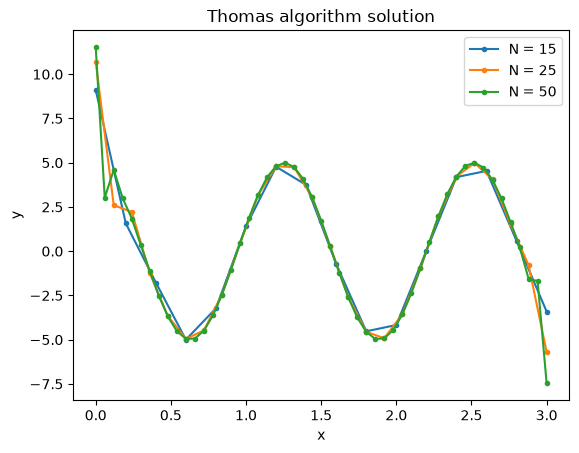

In [12]:
##Thomas ALgorithm

import numpy as np
import matplotlib.pyplot as plt

def f(j,n):
    result = np.sin(15*j/n)
    return result

N = [15,25,50]

def creating_arrayb(n):
    vectorB = np.random.rand(n+1,1)
    for i in range(0,n+1,1):
        if(i==0):
            vectorB[i]= (n/3)*((-5/2)*f(0,n) + 2*f(1,n) + (1/2)*f(2,n))
        elif(i==(n)):
            vectorB[i]= (n/3)*((5/2)*f(n,n) - 2*f((n-1),n) - (1/2)*f((n-2),n))
        else:
            vectorB[i] = n*(f(i+1,n) - f(i-1,n))
    #print(vectorB)
    return vectorB

def creating_ScalarTriangular_System(n):
    dia_main = []
    dia_up = []
    dia_down= []
    for i in range(0,n+1,1):
        if(i==0):
            dia_main.append(1)
            dia_down.append(1)
        elif(i==n):
            dia_main.append(1)
            dia_up.append(1)
        else:
            dia_main.append(4)
            dia_up.append(1)
            dia_down.append(1)
    return dia_main, dia_up, dia_down

def solve_system(n):
    dia_main, dia_up, dia_down = creating_ScalarTriangular_System(n)
    vectorB = creating_arrayb(n)
    b = np.array(dia_main, dtype=float)   
    c = np.array(dia_up, dtype=float)     
    a = np.array(dia_down, dtype=float)
    d = vectorB.flatten()
    for i in range(1, n+1):
        w = a[i-1] / b[i-1]
        b[i] = b[i] - w * c[i-1]
        d[i] = d[i] - w * d[i-1]
    y = np.zeros(n+1)
    y[n] = d[n] / b[n]
    for i in range(n-1, -1, -1):
        y[i] = (d[i] - c[i] * y[i+1]) / b[i]
    return y


for n in N:
    y = solve_system(n)
    x = 3 * np.arange(n+1) / n                   
    dm, du, dd = creating_ScalarTriangular_System(n)
    A = np.diag(dm) + np.diag(du, 1) + np.diag(dd, -1)

    plt.plot(x, y, marker='o', markersize=3, label=f'N = {n}')

xx = np.linspace(0, 3, 300)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Thomas algorithm solution')
plt.legend()
plt.show()